<div style="text-align:left;">
  
  <p><em>Prepared by Latreche Sara</em></p>
</div>

<center><font size=6><b>Exploratory Data Analysis for Breaset Cancer Dataset</b></font></center>

<div style="text-align:center;">
    <img src="plotly_app_breaset_cancer/assets/celltumor.PNG" width="400"/>
</div>


***

**Author**: Latreche Sara  
**Date**: /2025  

### Table of Contents

- [1 | Project Overview & Clinical Context](#1)
- [2 | Environment Setup & Data Loading](#2)
- [3 | Data Integrity & Initial Inspection](#3)
- [4 | Target Variable & Class Balance Analysis](#4)
- [5 | Distribution Analysis (KDE & Histograms)](#5)
- [6 | Spread, Outliers & Quantiles (Box & Violin Plots)](#6)
- [7 | Feature Interactions & Bivariate Analysis (Pair Plots)](#7)
- [8 | Correlation Matrix & Multicollinearity Assessment](#8)
- [9 | Key Insights & Preprocessing Recommendations](#9)
---

## <b>1 <span style='color:#e61227'>|</span> <a id='intro'>Project Overview and Objectives</a></b>



## <b>2 <span style='color:#e61227'>|</span> <a id='2'>Environment Setup & Data Loading</a></b>

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from plotly import express as px


## <b>3 <span style='color:#e61227'>|</span> <a id='3'>Data Integrity & Initial Inspection</a></b>

In [27]:
df=pd.read_csv("data.csv")

In [3]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [15]:
df.drop(columns=['id','Unnamed: 32']).describe().T.style.background_gradient(cmap="cubehelix",axis=0)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.000000,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.110000
texture_mean,569.000000,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.280000
perimeter_mean,569.000000,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.500000
area_mean,569.000000,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.000000
smoothness_mean,569.000000,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.163400
compactness_mean,569.000000,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.345400
concavity_mean,569.000000,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.426800
concave points_mean,569.000000,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.201200
symmetry_mean,569.000000,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.304000
fractal_dimension_mean,569.000000,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.097440


In [16]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [17]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [28]:
df.drop(columns=['id','Unnamed: 32'],inplace=True)

## <b>4 <span style='color:#e61227'>|</span> <a id='4'>Target Variable & Class Balance Analysis</a></b>

In [19]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

<Axes: xlabel='diagnosis', ylabel='count'>

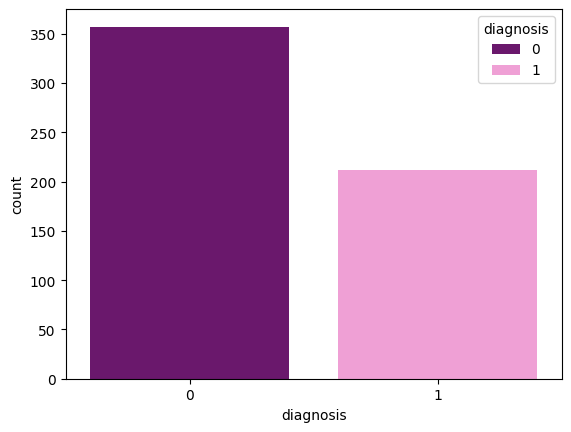

In [70]:

sns.countplot(
    data=df, 
    x='diagnosis', 
    hue='diagnosis', 
    palette=[ "#770A7A","#FC93D9"]
)

## <b>5 <span style='color:#e61227'>|</span> <a id='5'>Distribution Analysis (KDE & Histograms)</a></b>

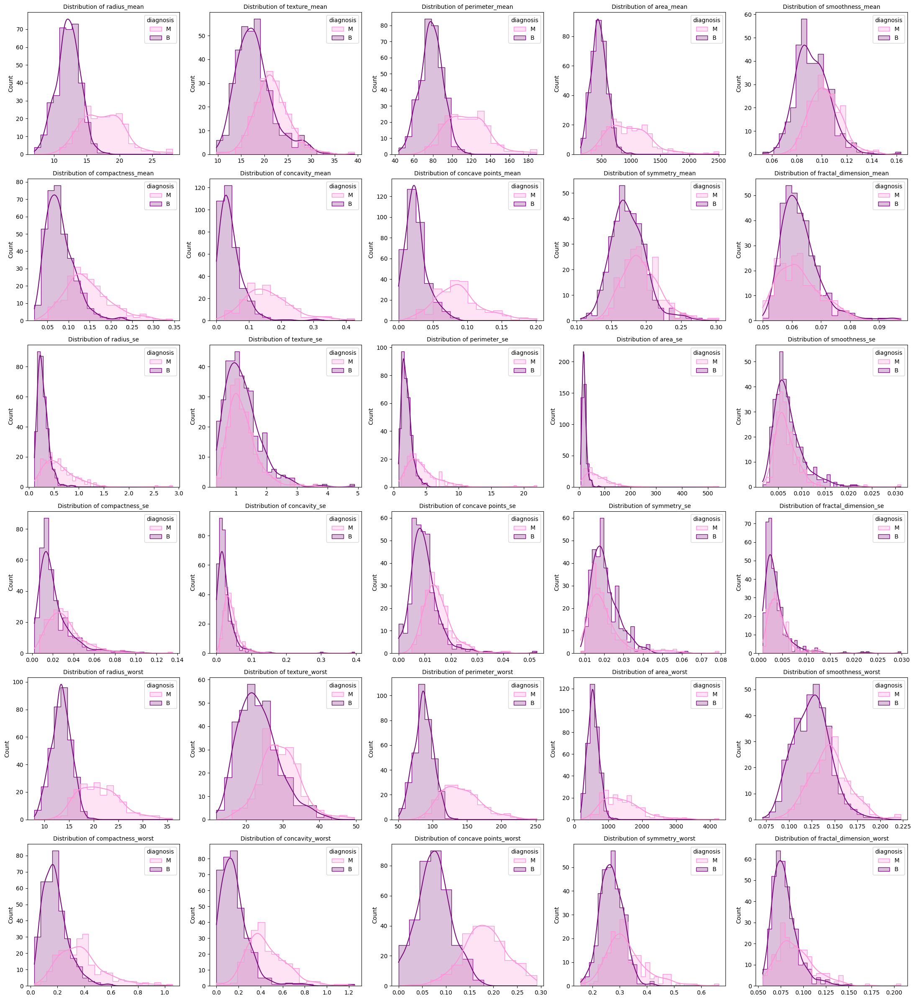

In [ ]:

# 1. Get all the numeric columns you want to plot (excluding 'id' and 'diagnosis')
# We slice from 1: to exclude 'id', and filter out 'diagnosis' if it's there
cols_to_plot = [col for col in df.columns[1:] if col != 'diagnosis']

# 2. Reshape the columns into a 6x5 grid array for the mosaic layout
grid_layout = [cols_to_plot[i:i+5] for i in range(0, len(cols_to_plot), 5)]

# 3. Create the mosaic figure
fig, axd = plt.subplot_mosaic(grid_layout, figsize=(22, 24))

# 4. Loop through the columns and plot them directly into their mosaic spot
for col in cols_to_plot:
    sns.histplot(
        data=df,
        x=col,
        hue='diagnosis',
        palette=["#FC93D9", "#770A7A"],
        kde=True,
        ax=axd[col],       # <--- This places it perfectly in the mosaic grid
        element="step"     # Makes the overlap cleaner to read
    )
    axd[col].set_title(f"Distribution of {col}", fontsize=10)
    axd[col].set_xlabel("") # Cleans up redundant x-labels to save space

# Adjust spacing so titles don't overlap with plots above them
plt.tight_layout()
plt.show()

## <b>6 <span style='color:#e61227'>|</span> <a id='6'>Spread, Outliers & Quantiles (Box & Violin Plots)</a></b>

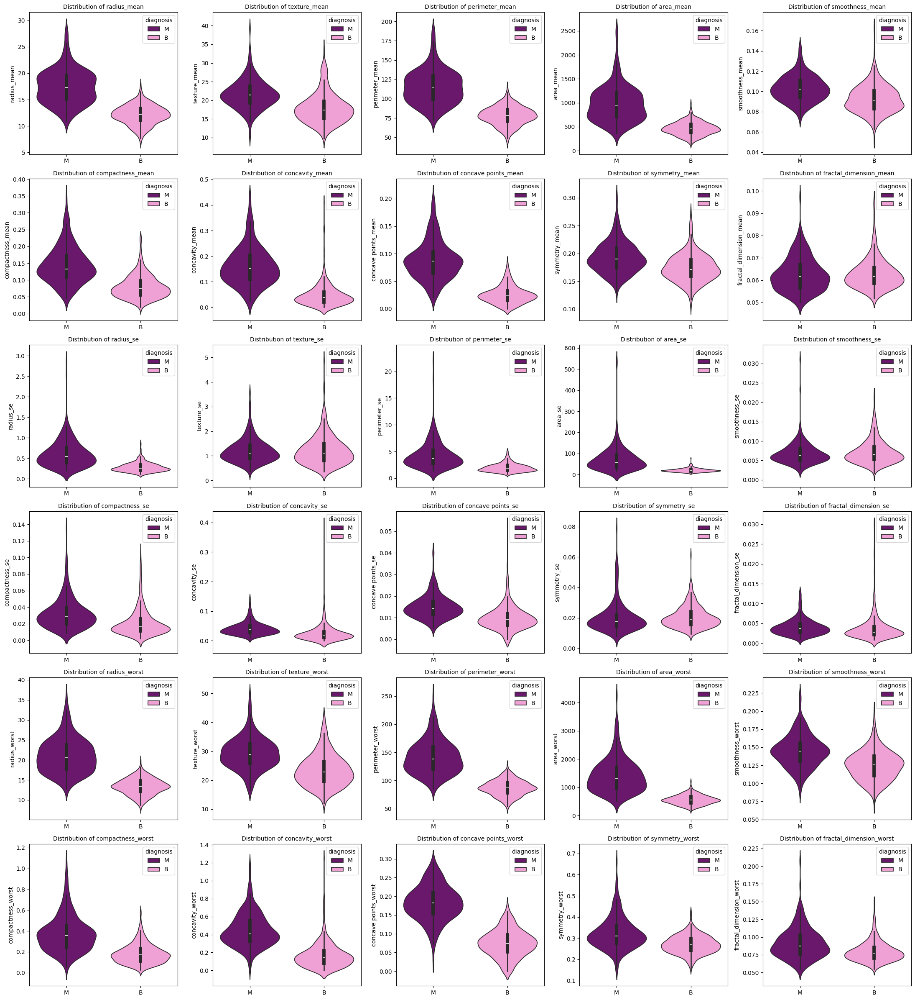

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get all numeric columns
cols_to_plot = [col for col in df.columns if col != 'diagnosis']

# 2. Reshape into a 6x5 grid array
grid_layout = [cols_to_plot[i:i+5] for i in range(0, len(cols_to_plot), 5)]

# 3. Create the mosaic figure
fig, axd = plt.subplot_mosaic(grid_layout, figsize=(22, 24))

# 4. Loop through the columns and plot
for col in cols_to_plot:
    sns.violinplot(
        data=df,
        x='diagnosis',                  # Places Benign/Malignant side-by-side
        y=col,                          # Puts the feature values on the vertical axis
        hue='diagnosis',                # Applies the colors based on diagnosis
        palette=[ "#770A7A","#FC93D9"], 
        legend=True,                   # Hides redundant individual legends
        ax=axd[col]                     # Places it perfectly in the mosaic grid
    )
    axd[col].set_title(f"Distribution of {col}", fontsize=10)
    axd[col].set_xlabel("")             # Cleans up redundant x-labels

# Adjust spacing so titles don't overlap
plt.tight_layout()
plt.show()

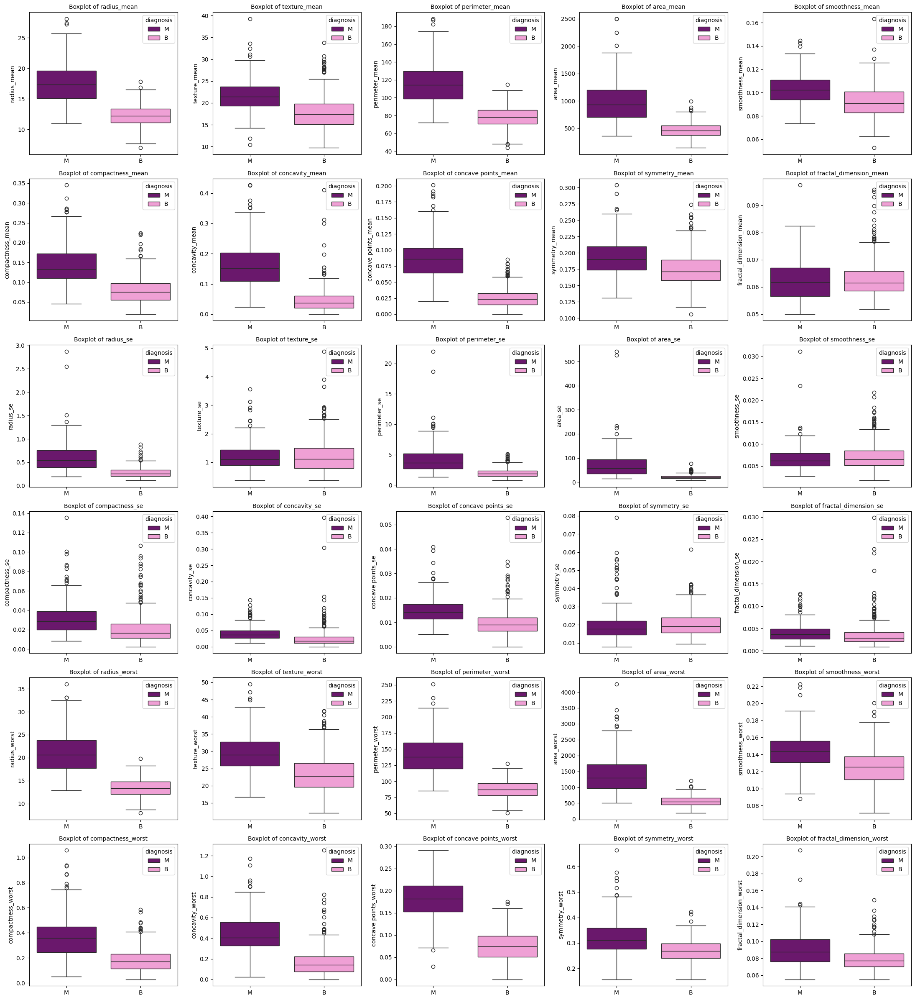

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get all numeric columns
cols_to_plot = [col for col in df.columns if col != 'diagnosis']

# 2. Reshape into a 6x5 grid array
grid_layout = [cols_to_plot[i:i+5] for i in range(0, len(cols_to_plot), 5)]

# 3. Create the mosaic figure
fig, axd = plt.subplot_mosaic(grid_layout, figsize=(22, 24))

# 4. Loop through the columns and plot boxplots
for col in cols_to_plot:
    sns.boxplot(
        data=df,
        x='diagnosis',                  # Places Benign/Malignant side-by-side
        y=col,                          # Puts the feature values on the vertical axis
        hue='diagnosis',                # Applies the colors based on diagnosis
        palette=[ "#770A7A","#FC93D9"], 
        legend=True,                   # Hides redundant individual legends
        ax=axd[col]                     # Places it perfectly in the mosaic grid
    )
    axd[col].set_title(f"Boxplot of {col}", fontsize=10)
    axd[col].set_xlabel("")             # Cleans up redundant x-labels

# Adjust spacing so titles don't overlap
plt.tight_layout()
plt.show()

## <b>7 <span style='color:#e61227'>|</span> <a id='7'>Feature Interactions & Bivariate Analysis (Pair Plots)</a></b>

In [51]:
plt.figure(figsize=(20,20))
sns.pairplot(df,hue='diagnosis',palette=['#FC93D9','#770A7A'])

<Figure size 2000x2000 with 0 Axes>

In [60]:
df['diagnosis'] = df['diagnosis'].map({'M':1,'B':0})

## <b>8 <span style='color:#e61227'>|</span> <a id='8'>Correlation Matrix & Multicollinearity Assessment</a></b>

In [61]:
corr=df.corr()

In [69]:
# get the absolute value of the corrlations
cor_target= abs(corr['diagnosis'])
# select the highly correlated features
relevant_features= cor_target[cor_target>0.5]

# collect the names of the features
names=[index for index,value in relevant_features.items()]

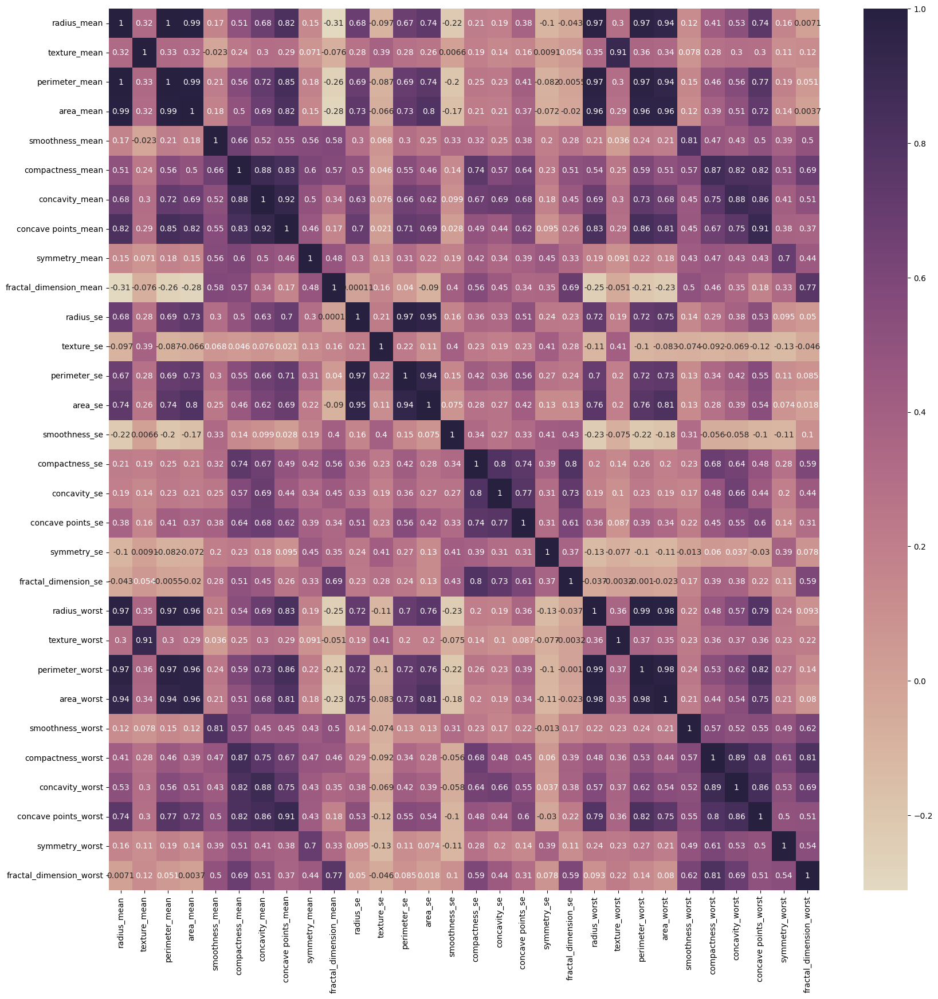

In [68]:

plt.figure(figsize=(20, 20))

# Drop the text column so ONLY pure numbers are calculated
numeric_corr = df.drop(columns=['diagnosis'], errors='ignore').corr()

sns.heatmap(
    numeric_corr, 
    annot=True, 
    cmap=sns.color_palette("ch:s=-.2,r=.6", as_cmap=True) # Makes sure it acts as a smooth gradient map
)

plt.show()


## <b>9 <span style='color:#e61227'>|</span> <a id='9'>Key Insights & Preprocessing Recommendations</a></b>

### 💡 Core Insights from EDA

1. **Clear Class Separation (Distribution Plots):**
   * **Observation:** Our KDE and histogram mosaics show that features like `radius_mean`, `perimeter_mean`, and `concavity_mean` display distinct shifts. Malignant tumors consistently exhibit significantly larger mean values compared to benign tumors.
   * **Takeaway:** This indicates that linear boundaries will likely be highly effective, making **Logistic Regression** an excellent choice for a baseline model.

2. **Extreme Outliers & Variance (Box & Violin Plots):**
   * **Observation:** The box and violin plots reveal that several features (specifically standard error features like `area_se` and `smoothness_se`) have heavily right-skewed distributions with prominent outliers.
   * **Takeaway:** Distance-based models and optimization algorithms (like gradient descent in Logistic Regression) are highly sensitive to these scale differences and extreme values.

3. **Severe Multicollinearity (Heatmap & Pair Plots):**
   * **Observation:** The correlation heatmap reveals massive blocks of dark/bright spots where $r \ge 0.90$. For example, `radius_mean`, `perimeter_mean`, and `area_mean` are almost perfectly collinear because they are geometrically dependent. Similarly, `mean` and `worst` features are highly redundant.
   * **Takeaway:** Feeding all these features into a traditional model will destabilize the coefficient weights, making it impossible for a physician to interpret which cellular feature actually drives the cancer diagnosis.

---

### 🛠️ Strategic Preprocessing Recommendations

Based on our exploratory data analysis, we must implement the following four preprocessing steps before training our models:

#### 1. Address Multicollinearity via Variance Inflation Factor (VIF)
* **Action:** Instead of keeping all 30+ features, we will write an iterative loop to calculate VIF. We should systematically drop features with a **VIF > 10** until only linearly independent features remain. 
* **Goal:** This creates our "Reduced Feature Set," ensuring stable, reliable, and interpretable model coefficients.

#### 2. Feature Scaling (Standardization)
* **Action:** Because features like `area_mean` span values up to 2500, while `smoothness_mean` spans values less than 0.1, we must apply **Standardization** (Z-score normalization).
* **Goal:** Center the features at a mean of 0 and a standard deviation of 1. This prevents features with large magnitudes from dominating the loss function during model training.

#### 3. Stratified Data Splitting
* **Action:** When splitting the data into training and testing sets, we must use **Stratified Sampling** (`stratify=y` in scikit-learn).
* **Goal:** This guarantees that the exact proportions of Malignant and Benign cases are perfectly preserved across both the training set and the validation set, preventing evaluation bias.

#### 4. Prioritize Clinical Evaluation Metrics (Recall & F1-Score)
* **Action:** While accuracy is a helpful baseline, we must prioritize minimizing **False Negatives** (predicting a tumor is benign when it is actually malignant).
* **Goal:** We will focus on optimizing the **Recall (Sensitivity)** and the **F1-Score**, ensuring the model is optimized for patient safety.